In [1]:
import numpy as np
import pandas as pd

In [2]:
#importing the file
df=pd.read_csv('../data/raw/Tweets.csv')
df.head(10)

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)
5,570300767074181121,negative,1.0000,Can't Tell,0.6842,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica seriously would pay $30 a fligh...,NaN,2015-02-24 11:14:33 -0800,NaN,Pacific Time (US & Canada)
6,570300616901320704,positive,0.6745,NaN,0.0000,Virgin America,NaN,cjmcginnis,NaN,0,"@VirginAmerica yes, nearly every time I fly VX...",NaN,2015-02-24 11:13:57 -0800,San Francisco CA,Pacific Time (US & Canada)
7,570300248553349120,neutral,0.6340,NaN,NaN,Virgin America,NaN,pilot,NaN,0,@VirginAmerica Really missed a prime opportuni...,NaN,2015-02-24 11:12:29 -0800,Los Angeles,Pacific Time (US & Canada)
8,570299953286942721,positive,0.6559,NaN,NaN,Virgin America,NaN,dhepburn,NaN,0,"@virginamerica Well, I didn't…but NOW I DO! :-D",NaN,2015-02-24 11:11:19 -0800,San Diego,Pacific Time (US & Canada)
9,570295459631263746,positive,1.0000,NaN,NaN,Virgin America,NaN,YupitsTate,NaN,0,"@VirginAmerica it was amazing, and arrived an ...",NaN,2015-02-24 10:53:27 -0800,Los Angeles,Eastern Time (US & Canada)


In [3]:
df.shape

(14640, 15)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  str    
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   str    
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  str    
 6   airline_sentiment_gold        40 non-null     str    
 7   name                          14640 non-null  str    
 8   negativereason_gold           32 non-null     str    
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  str    
 11  tweet_coord                   1019 non-null   str    
 12  tweet_created                 14640 non-null  str    
 13  tweet_locati

# Checking negative reason 

In [18]:
df['airline_sentiment'].value_counts()

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

In [4]:
df['negativereason'].isna().sum()

np.int64(5462)

In [5]:
neg_reason=pd.crosstab(df['airline_sentiment'],df['negativereason'])
neg_reason

negativereason,Bad Flight,Can't Tell,Cancelled Flight,Customer Service Issue,Damaged Luggage,Flight Attendant Complaints,Flight Booking Problems,Late Flight,Lost Luggage,longlines
airline_sentiment,,,,,,,,,,
negative,580,1190,847,2910,74,481,529,1665,724,178


In [6]:
neg_reason.sum(axis=1)

airline_sentiment
negative    9178
dtype: int64

The negativereason column contains many null values, but these are expected rather than missing due to data-quality issues. The number of null values (5,462) matches the total number of posi

# Checking negative reason confidence

In [7]:
#checking whether all negative tweets have negative reason confidence
negative_tweets=df[df['airline_sentiment']=='negative']
print(negative_tweets['negativereason_confidence'].isna().sum())

0


In [8]:
negative_tweets['negativereason_confidence'].isna().sum()

np.int64(0)

Among all negative tweets, there are no missing values in negativereason_confidence. The missing values occur only for positive and neutral tweets, where this field is not applicable. Therefore, the column will be kept unchanged for now.

In [9]:
negative_tweets[['negativereason','negativereason_confidence']].isna().sum()

negativereason               0
negativereason_confidence    0
dtype: int64

In [10]:
pos_neu=df[(df['airline_sentiment']=='positive') | (df['airline_sentiment']=='neutral')]
pos_neu.shape

(5462, 15)

In [11]:
pos_neu['negativereason'].isna().sum()

np.int64(5462)

In [45]:
pos_neu['negativereason_confidence'].isna().sum()

np.int64(4118)

In [17]:
pos_neu['negativereason_confidence'].value_counts()

negativereason_confidence
0.0    1344
Name: count, dtype: int64

**Finding: `negativereason_confidence` for positive and neutral tweets**

- Of the 5,462 positive and neutral tweets, 4,118 have NaN and the other 1,344 have exactly 0.0 in `negativereason_confidence`. No other values appear in this group.
- Both encodings mean the same thing: no negative reason applies. A 0.0 here is not a real confidence of zero.
- Because pandas treats 0.0 as a real value, `isna()` counted only the 4,118 NaN rows. That is why the count came out lower than 5,462.
- Averaging this column without separating the classes would include the 1,344 zeros and give a misleadingly low mean.

**Decision:** convert the 0.0 values to NaN for non-negative tweets, so "not applicable" has a single encoding that matches `negativereason`. The column is kept for now and will be dropped in the column-removal step of this notebook, since the baseline model only uses `text` and `airline_sentiment`.

In [18]:
mask = df['airline_sentiment'] != 'negative'
df.loc[mask, 'negativereason_confidence'] = np.nan

## Tweet created

In [27]:
df['tweet_created']=pd.to_datetime(df['tweet_created'])

In [29]:
df['tweet_created'].dtype

datetime64[us, UTC-08:00]

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype                    
---  ------                        --------------  -----                    
 0   tweet_id                      14640 non-null  int64                    
 1   airline_sentiment             14640 non-null  str                      
 2   airline_sentiment_confidence  14640 non-null  float64                  
 3   negativereason                9178 non-null   str                      
 4   negativereason_confidence     9178 non-null   float64                  
 5   airline                       14640 non-null  str                      
 6   airline_sentiment_gold        40 non-null     str                      
 7   name                          14640 non-null  str                      
 8   negativereason_gold           32 non-null     str                      
 9   retweet_count                 14640 non-null  int6

# Tweet coordinates

In [40]:
df.drop('tweet_coord', axis=1,inplace=True)

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype                    
---  ------                        --------------  -----                    
 0   tweet_id                      14640 non-null  int64                    
 1   airline_sentiment             14640 non-null  str                      
 2   airline_sentiment_confidence  14640 non-null  float64                  
 3   negativereason                9178 non-null   str                      
 4   negativereason_confidence     9178 non-null   float64                  
 5   airline                       14640 non-null  str                      
 6   airline_sentiment_gold        40 non-null     str                      
 7   name                          14640 non-null  str                      
 8   negativereason_gold           32 non-null     str                      
 9   retweet_count                 14640 non-null  int6

## Airline sentiment gold & Negative reason gold- very few non null values
Also Airline sentiment gold copies the target- so dropping both

In [42]:
df.drop(columns=['airline_sentiment_gold','negativereason_gold'],inplace=True)

In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype                    
---  ------                        --------------  -----                    
 0   tweet_id                      14640 non-null  int64                    
 1   airline_sentiment             14640 non-null  str                      
 2   airline_sentiment_confidence  14640 non-null  float64                  
 3   negativereason                9178 non-null   str                      
 4   negativereason_confidence     9178 non-null   float64                  
 5   airline                       14640 non-null  str                      
 6   name                          14640 non-null  str                      
 7   retweet_count                 14640 non-null  int64                    
 8   text                          14640 non-null  str                      
 9   tweet_created                 14640 non-null  date

## User timezone and tweet location 

User time zone - It’s  about 33% null (4,820 rows), so it describes a subset of users.
It describes the user, not the tweet. A person’s timezone setting says nothing about how a sentence reads.
It can’t be used at inference. Someone pasting text into your website won’t supply it.


Tweet location - 48% null and mostly free text(eg newyork appears in different form. Can' be used at inference
 

In [50]:
df.drop(columns=['user_timezone','tweet_location'],inplace=True)

In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype                    
---  ------                        --------------  -----                    
 0   tweet_id                      14640 non-null  int64                    
 1   airline_sentiment             14640 non-null  str                      
 2   airline_sentiment_confidence  14640 non-null  float64                  
 3   negativereason                9178 non-null   str                      
 4   negativereason_confidence     9178 non-null   float64                  
 5   airline                       14640 non-null  str                      
 6   name                          14640 non-null  str                      
 7   retweet_count                 14640 non-null  int64                    
 8   text                          14640 non-null  str                      
 9   tweet_created                 14640 non-null  date

## name- irrelavant in sentiment analysis

In [54]:
df.drop('name',axis=1, inplace=True)

In [55]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype                    
---  ------                        --------------  -----                    
 0   tweet_id                      14640 non-null  int64                    
 1   airline_sentiment             14640 non-null  str                      
 2   airline_sentiment_confidence  14640 non-null  float64                  
 3   negativereason                9178 non-null   str                      
 4   negativereason_confidence     9178 non-null   float64                  
 5   airline                       14640 non-null  str                      
 6   retweet_count                 14640 non-null  int64                    
 7   text                          14640 non-null  str                      
 8   tweet_created                 14640 non-null  datetime64[us, UTC-08:00]
dtypes: datetime64[us, UTC-08:00](1), float64(2), int64(

In [56]:
df['tweet_id'].nunique()

14485

In [59]:
id_counts=df['tweet_id'].value_counts()
id_counts[id_counts>1]

tweet_id
570308309682675712    2
570308064185880577    2
570307949614256128    2
570307948171423745    2
570307434113310720    2
                     ..
569680231012773888    2
569622568459636736    2
569621879633391616    2
569601363799359488    2
569600137296633856    2
Name: count, Length: 155, dtype: int64

In [60]:
# 1. Rows whose tweet_id appears more than once
id_counts = df['tweet_id'].value_counts()
dup_ids = id_counts[id_counts > 1].index
dups = df[df['tweet_id'].isin(dup_ids)]
print(len(dup_ids), len(dups))          # 155, 310

# 2. Distinct sentiment labels per duplicated ID
n_labels = dups.groupby('tweet_id')['airline_sentiment'].nunique()
print((n_labels == 1).sum())            # agreeing pairs: 137
print((n_labels == 2).sum())            # conflicting pairs: 18

# 3. The conflicting pairs side by side
conflict_ids = n_labels[n_labels > 1].index
conflicts = (dups[dups['tweet_id'].isin(conflict_ids)]
             .sort_values('tweet_id')
             [['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'text']])
conflicts

155 310
137
18


,tweet_id,airline_sentiment,airline_sentiment_confidence,text
12019,570268326250745856,neutral,0.6304,@AmericanAir my flight to DFW from LIT on my w...
12180,570268326250745856,negative,0.6670,@AmericanAir my flight to DFW from LIT on my w...
12177,570268875872473088,negative,0.6432,@AmericanAir I was happy to purchase the upgra...
12016,570268875872473088,positive,0.6907,@AmericanAir I was happy to purchase the upgra...
12011,570270435478122497,neutral,0.6266,@AmericanAir Thanks so much!
12172,570270435478122497,positive,1.0000,@AmericanAir Thanks so much!
12165,570271574462369793,positive,1.0000,@AmericanAir we are off to Kax premium. Hopin...
12004,570271574462369793,neutral,0.6270,@AmericanAir we are off to Kax premium. Hopin...
12003,570271896887017472,positive,0.3519,@AmericanAir thanks for the info Is there a nu...
12164,570271896887017472,neutral,0.6710,@AmericanAir thanks for the info Is there a nu...


55 IDs appear twice (310 rows)
137 of those 155 pairs have the same sentiment label on both rows
18 of those 155 pairs have two different sentiment labels

In [61]:
#drop each conflicting pairs
df = df[~df['tweet_id'].isin(conflict_ids)]
df.shape       

(14604, 9)

In [ ]:
#keep one row for each agreeing pair
df = df.drop_duplicates(subset='tweet_id', keep='first').reset_index(drop=True)
df.shape        

(14467, 9)

In [ ]:
df['tweet_id'].nunique() == len(df)     #verifying

True

In [66]:
df['airline_sentiment'].value_counts()  

airline_sentiment
negative    9081
neutral     3060
positive    2326
Name: count, dtype: int64

In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14467 entries, 0 to 14466
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype                    
---  ------                        --------------  -----                    
 0   tweet_id                      14467 non-null  int64                    
 1   airline_sentiment             14467 non-null  str                      
 2   airline_sentiment_confidence  14467 non-null  float64                  
 3   negativereason                9081 non-null   str                      
 4   negativereason_confidence     9081 non-null   float64                  
 5   airline                       14467 non-null  str                      
 6   retweet_count                 14467 non-null  int64                    
 7   text                          14467 non-null  str                      
 8   tweet_created                 14467 non-null  datetime64[us, UTC-08:00]
dtypes: datetime64[us, UTC-08:00](1), float64(2), int64(

In [68]:
df.describe()

,tweet_id,airline_sentiment_confidence,negativereason_confidence,retweet_count
count,1.446700e+04,14467.000000,9081.000000,14467.000000
mean,5.692059e+17,0.900182,0.731574,0.083500
std,7.752263e+14,0.162834,0.238400,0.750092
min,5.675883e+17,0.335000,0.312200,0.000000
25%,5.685495e+17,0.692400,0.645200,0.000000
50%,5.694366e+17,1.000000,0.680600,0.000000
75%,5.698802e+17,1.000000,1.000000,0.000000
max,5.703106e+17,1.000000,1.000000,44.000000


<Axes: xlabel='airline_sentiment_confidence', ylabel='Count'>

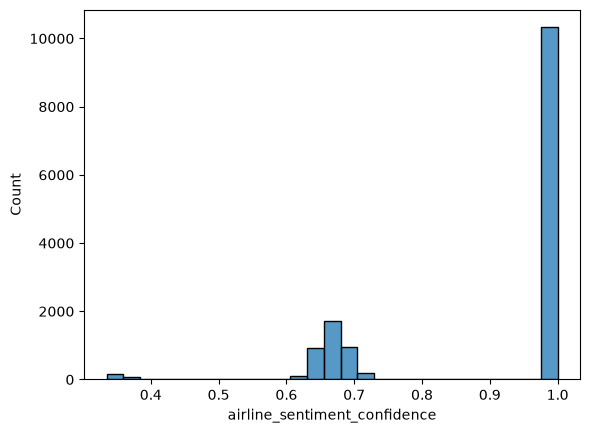

In [70]:
import seaborn as sns
sns.histplot(df['airline_sentiment_confidence'])

In [71]:
df['airline_sentiment_confidence'].value_counts()

airline_sentiment_confidence
1.0000    10322
0.6667       71
0.6632       35
0.6559       30
0.6596       30
          ...  
0.7257        1
0.7241        1
0.6384        1
0.7094        1
0.3487        1
Name: count, Length: 1018, dtype: int64

## Confidence filter

**What `airline_sentiment_confidence` shows**
- The histogram has three groups: about 10,300 rows at exactly 1.0 (unanimous labels), a cluster of about 3,900 rows between 0.6 and 0.8 (peaking near 0.67, majority-agreed labels), and a small group of 234 rows between 0.34 and 0.39.
- There is almost nothing between the groups. Only 1 row falls between 0.4 and 0.6.

**Why the low group is a problem**
- A confidence this low means the annotators barely agreed, so the label is close to a guess. Several examples look wrong on reading (for example, a clearly negative "tacky" complaint labeled positive).
- The model learns from these labels, so noisy ones add confusion, and they make test scores less reliable.

**Decision:** remove rows with `airline_sentiment_confidence` below 0.5.
- Any cutoff between 0.4 and 0.59 removes the same 234 rows (1.6% of the data), so 0.5 is simply the middle of the gap.
- The 0.6 to 0.8 cluster is kept on purpose. Those labels were still agreed by a majority, and removing them would cost about a quarter of the data.
- Class impact: neutral loses about 3% of its rows, positive about 3%, negative under 1%, so the class balance barely moves.

In [72]:
df=df[df['airline_sentiment_confidence']>=0.5].reset_index(drop=True)
df.shape

(14233, 9)

In [73]:
df['airline_sentiment_confidence'].min()

np.float64(0.5918)

In [75]:
# Encoding the labels
label_map={'negative':0,'neutral':1,'positive':2}
df['label']=df['airline_sentiment'].map(label_map)

In [79]:
df['label'].isna().sum()      


np.int64(0)

In [77]:
df['label'].value_counts()  

label
0    9018
1    2959
2    2256
Name: count, dtype: int64

In [80]:
df.shape     

(14233, 10)

In [81]:
df[['text', 'label']].isna().sum()

text     0
label    0
dtype: int64

In [82]:
df['tweet_id'].is_unique   

True

In [83]:
df['label'].value_counts(normalize=True) 

label
0    0.633598
1    0.207897
2    0.158505
Name: proportion, dtype: float64

In [85]:
from pathlib import Path

Path('../data/processed').mkdir(parents=True, exist_ok=True)
df.to_csv('../data/processed/tweets_clean.csv', index=False)